<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E8%A9%95%E4%BC%B0%E6%8C%87%E6%A8%99/precision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎯 精確率 (Precision)

> **一句話記住**：精確率在問 —— **模型說「是」的那些，有幾個真的是？**
> 精確率高 = 模型**不亂喊**、很少「誤報」。

📚 [回到評估指標總覽](./README.md)

## 🎯 學完這份筆記本，你會…
- 手算與用 `sklearn` 算出精確率
- 判斷什麼情境「**誤報 (FP) 很貴**」，需要重視精確率

---

## 📬 生活情境：垃圾信過濾器

信箱把 4 封信丟進「垃圾信匣」，結果其中 1 封是**老闆的重要信** 😱

> 精確率 = 垃圾信匣裡「真的是垃圾信」的比例 = 3 ÷ 4 = **75%**

被誤丟的那封就是 **FP（假正例）**。精確率越高，你越不會錯過重要的信。

## 📐 公式

$$\text{Precision} = \frac{TP}{TP + FP} = \frac{\text{猜「是」而且猜對}}{\text{所有猜「是」的}}$$

**白話讀法**：分母是「模型舉手說是的全部」，分子是「其中真的是的」。只看混淆矩陣的**「猜是」那一欄**。

---
### 【步驟 0】環境準備：載入套件與中文字型

> 這一格只要**按執行**就好，不用看懂。它會幫你安裝中文字型，讓圖表上的中文不會變成 □□□。

In [1]:
# 【步驟 0】載入套件與設定中文字型（Colab / Mac / Windows 通用）
import os, glob, sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import mplfonts
except ImportError:  # Colab 第一次執行時自動安裝
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mplfonts"])
    import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")

# 統一圖表風格：去掉上、右邊框，讓畫面更乾淨
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "figure.dpi": 100,
})
BLUE, GREEN, RED, ORANGE, PURPLE, GRAY = "#3182ce", "#38a169", "#e53e3e", "#dd6b20", "#805ad5", "#a0aec0"

print("✅ 套件與中文字型載入完成！")

✅ 套件與中文字型載入完成！


---
### 【步驟 1】準備資料：10 封信，`1` = 垃圾信、`0` = 正常信

In [2]:
# 學生可以透過 prompt: "定義垃圾信過濾情境的 y_true 與 y_pred，並列出所有「被預測為垃圾信」的信件"
y_true = [1, 0, 0, 1, 0, 1, 0, 0, 1, 0]  # 實際：1=垃圾信、0=正常信
y_pred = [1, 0, 1, 1, 0, 0, 0, 0, 1, 0]  # 過濾器的預測

df = pd.DataFrame({
    "信件": [f"第{i+1}封" for i in range(10)],
    "實際": ["垃圾" if t else "正常" for t in y_true],
    "預測": ["垃圾" if p else "正常" for p in y_pred],
})
print("📥 被丟進「垃圾信匣」的信（模型說是垃圾的）：")
display(df[df["預測"] == "垃圾"])

📥 被丟進「垃圾信匣」的信（模型說是垃圾的）：


,信件,實際,預測
0,第1封,垃圾,垃圾
2,第3封,正常,垃圾
3,第4封,垃圾,垃圾
8,第9封,垃圾,垃圾


#### 👀 看懂結果
模型把 4 封信判為垃圾信，其中**第 3 封其實是正常信** → 這就是 FP。

---
### 【步驟 2】手算精確率，再用 sklearn 驗證

In [3]:
# 學生可以透過 prompt: "計算 TP 與 FP，依公式 TP/(TP+FP) 手算精確率（避免除以零），並用 sklearn 的 precision_score 驗證"
from sklearn.metrics import precision_score

TP = sum((t == 1 and p == 1) for t, p in zip(y_true, y_pred))
FN = sum((t == 1 and p == 0) for t, p in zip(y_true, y_pred))
FP = sum((t == 0 and p == 1) for t, p in zip(y_true, y_pred))
TN = sum((t == 0 and p == 0) for t, p in zip(y_true, y_pred))

precision = TP / (TP + FP) if (TP + FP) > 0 else 0   # 模型都沒說「是」時，避免除以 0

print(f"模型說是垃圾信：{TP + FP} 封（TP={TP} + FP={FP}）")
print(f"其中真的是垃圾：{TP} 封")
print(f"📝 手算精確率      ：{precision:.2f}")
print(f"🤖 sklearn 精確率 ：{precision_score(y_true, y_pred):.2f}")

模型說是垃圾信：4 封（TP=3 + FP=1）
其中真的是垃圾：3 封
📝 手算精確率      ：0.75
🤖 sklearn 精確率 ：0.75


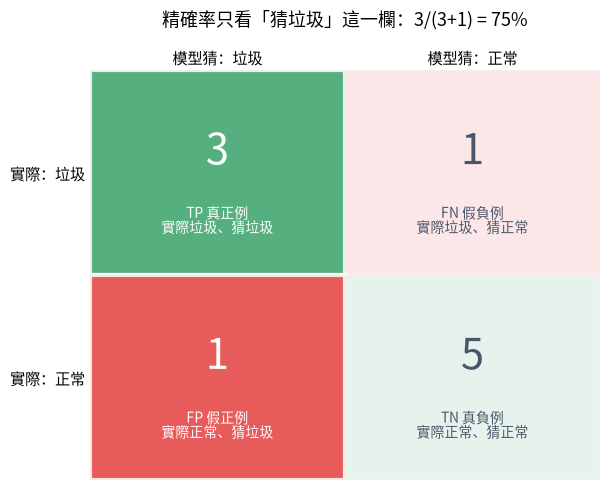

In [4]:
# 🛠️ 畫圖小工具：畫出「好讀版」混淆矩陣（不用背，會用就好）
def draw_confusion(TP, FN, FP, TN, pos="正類", neg="負類", highlight=None, title="混淆矩陣"):
    """highlight 可傳入要強調的格子，例如 ["TP", "FP"]；其他格子會變淡。"""
    cells = {
        "TP": (0, 0, TP, f"TP 真正例\n實際{pos}、猜{pos}", GREEN),
        "FN": (0, 1, FN, f"FN 假負例\n實際{pos}、猜{neg}", RED),
        "FP": (1, 0, FP, f"FP 假正例\n實際{neg}、猜{pos}", RED),
        "TN": (1, 1, TN, f"TN 真負例\n實際{neg}、猜{neg}", GREEN),
    }
    fig, ax = plt.subplots(figsize=(6.2, 5))
    for key, (r, c, n, label, color) in cells.items():
        alpha = 0.85 if (highlight is None or key in highlight) else 0.12
        ax.add_patch(plt.Rectangle((c, 1 - r), 1, 1, color=color, alpha=alpha, ec="white", lw=3))
        txt_color = "white" if alpha > 0.5 else "#4a5568"
        ax.text(c + 0.5, 1.62 - r, str(n), ha="center", va="center", fontsize=30, color=txt_color)
        ax.text(c + 0.5, 1.27 - r, label, ha="center", va="center", fontsize=10, color=txt_color)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2)
    ax.set_xticks([0.5, 1.5]); ax.set_xticklabels([f"模型猜：{pos}", f"模型猜：{neg}"], fontsize=11)
    ax.set_yticks([1.5, 0.5]); ax.set_yticklabels([f"實際：{pos}", f"實際：{neg}"], fontsize=11)
    ax.xaxis.tick_top()
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(title, pad=32)
    plt.tight_layout()
    plt.show()

draw_confusion(TP, FN, FP, TN, pos="垃圾", neg="正常", highlight=["TP", "FP"],
               title=f"精確率只看「猜垃圾」這一欄：{TP}/({TP}+{FP}) = {precision:.0%}")

#### 👀 看懂結果
精確率只在乎**左邊那一欄**（模型說是垃圾的）。注意第 6 封垃圾信**沒被抓到 (FN)**，但精確率**完全不管它** —— 這正是精確率的盲點，要靠下一份的[召回率](./recall.ipynb)來補。

---
### 【步驟 3】實驗：「謹慎型」vs「衝動型」過濾器

- **謹慎型**：非常確定才丟垃圾信匣 → 丟得少，但很少丟錯
- **衝動型**：有點可疑就丟 → 丟得多，也常丟錯

謹慎型：精確率 1.00
原本的：精確率 0.75
衝動型：精確率 0.50


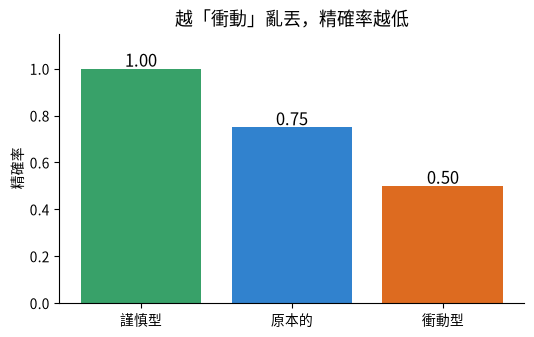

In [5]:
# 學生可以透過 prompt: "比較謹慎型與衝動型兩個模型的精確率，並用長條圖呈現"
y_pred_careful = [1, 0, 0, 1, 0, 0, 0, 0, 0, 0]   # 只丟 2 封，都丟對
y_pred_eager   = [1, 1, 1, 1, 0, 1, 1, 0, 1, 1]   # 丟 8 封，錯了 4 封

results = {
    "謹慎型": precision_score(y_true, y_pred_careful),
    "原本的": precision_score(y_true, y_pred),
    "衝動型": precision_score(y_true, y_pred_eager),
}
for name, p in results.items():
    print(f"{name}：精確率 {p:.2f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(results.keys(), results.values(), color=[GREEN, BLUE, ORANGE])
ax.bar_label(bars, fmt="%.2f", fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel("精確率")
ax.set_title("越「衝動」亂丟，精確率越低")
plt.show()

#### 👀 看懂結果
謹慎型精確率 **1.00**（說是就一定是），衝動型只有 **0.50**（丟進去的有一半是好信）。
不過謹慎型只抓到 2 封垃圾信，漏掉很多 —— 精確率高**不代表**抓得完整。

---
## 🧭 什麼時候要特別重視精確率？

當「**誤報 (FP) 的代價很高**」時：

| 情境 | 誤報 (FP) 的後果 |
| :--- | :--- |
| 📬 垃圾信過濾 | 重要的信被丟掉，錯過工作 |
| 🛒 推薦系統 | 推薦一堆不相關的商品，使用者覺得煩 |
| ⚖️ 自動檢舉 / 停權 | 冤枉好人，引發客訴 |

---
## ⚠️ 常見誤區

| 誤區 | 正確觀念 |
| :--- | :--- |
| 精確率高 = 模型很好 | 模型可能只是「很少說是」，漏掉很多（召回率低）。 |
| 精確率和準確率是一樣的 | 準確率看**全部**；精確率只看**模型說「是」的那一群**。 |

---
## ✍️ 隨堂練習

**練習**：一個模型說 20 封是垃圾信，其中 15 封真的是垃圾信。精確率是多少？

<details>
<summary>💡 點我看答案</summary>

TP = 15、FP = 20 − 15 = 5 → 精確率 = 15 ÷ 20 = **0.75**

</details>

---
## 📝 重點回顧

| 重點 | 內容 |
| :--- | :--- |
| 問題 | 說「是」的，有幾個真的是？ |
| 公式 | TP ÷ (TP + FP) |
| sklearn | `precision_score(y_true, y_pred)` |
| 重視時機 | **誤報 (FP) 代價高**：垃圾信、推薦、檢舉 |
| 下一步 | 👉 [召回率 Recall](./recall.ipynb) |

## 🤖 問問 AI
> 「精確率 (Precision) 和準確率 (Accuracy) 的差別是什麼？請用『射箭』或『釣魚』的比喻說明。」